# Prediccion de temperatura con una CNN 1D

## 1. Descripcion del problema

El objetivo es predecir la temperatura de la siguiente hora a partir de las temperaturas observadas durante las 24 horas anteriores. Para ello se utilizara una red neuronal convolucional unidimensional (CNN 1D).

Se trabajara con el conjunto de datos Jena Climate, que contiene registros meteorologicos. En este ejemplo se utilizara solamente la temperatura, por lo que el problema sera de prediccion de una serie de tiempo univariada.

Se compararan tres configuraciones sencillas de la CNN. La seleccion del modelo se realizara con los datos de validacion y la evaluacion final se hara con los datos de prueba.

## 2. Importacion de librerias

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv1D, GlobalMaxPooling1D, Dense, Dropout, Flatten
from tensorflow.keras.callbacks import EarlyStopping

## 3. Inspeccion del conjunto de datos

El archivo contiene observaciones meteorologicas tomadas aproximadamente cada 10 minutos. Se descarga el archivo comprimido y se leen sus datos directamente.

In [23]:
np.random.seed(42)
tf.random.set_seed(42)

origin = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
fname = "jena_climate_2009_2016.csv.zip"

ruta = tf.keras.utils.get_file(fname=fname, origin=origin)
df = pd.read_csv(ruta, compression="zip")

In [24]:
print(df.info())
print("Dimensiones:", df.shape)
display(df.head())
print("Columnas:", df.columns.tolist())
print("Valores faltantes:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420551 entries, 0 to 420550
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date Time        420551 non-null  object 
 1   p (mbar)         420551 non-null  float64
 2   T (degC)         420551 non-null  float64
 3   Tpot (K)         420551 non-null  float64
 4   Tdew (degC)      420551 non-null  float64
 5   rh (%)           420551 non-null  float64
 6   VPmax (mbar)     420551 non-null  float64
 7   VPact (mbar)     420551 non-null  float64
 8   VPdef (mbar)     420551 non-null  float64
 9   sh (g/kg)        420551 non-null  float64
 10  H2OC (mmol/mol)  420551 non-null  float64
 11  rho (g/m**3)     420551 non-null  float64
 12  wv (m/s)         420551 non-null  float64
 13  max. wv (m/s)    420551 non-null  float64
 14  wd (deg)         420551 non-null  float64
dtypes: float64(14), object(1)
memory usage: 48.1+ MB
None
Dimensiones: (420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


Columnas: ['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']
Valores faltantes:
Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0
dtype: int64


In [4]:
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.sort_values("Date Time").reset_index(drop=True)

print("Fecha inicial:", df["Date Time"].min())
print("Fecha final:", df["Date Time"].max())
print(df["T (degC)"].describe())

Fecha inicial: 2009-01-01 00:10:00
Fecha final: 2017-01-01 00:00:00
count    420551.000000
mean          9.450147
std           8.423365
min         -23.010000
25%           3.360000
50%           9.420000
75%          15.470000
max          37.280000
Name: T (degC), dtype: float64


## 4. Exploracion de los datos

Se examina la variable temperatura y su evolucion temporal. Para reducir el tiempo de entrenamiento se toma aproximadamente una observacion por hora, seleccionando una de cada seis filas.

In [5]:
datos = (df.set_index("Date Time")[["T (degC)"]].resample("1h").mean().dropna().reset_index())

datos = datos.rename(columns={"T (degC)": "temperatura"})
print("Observaciones seleccionadas:", len(datos))
display(datos.head())
print(datos["temperatura"].describe())

Observaciones seleccionadas: 70041


,Date Time,temperatura
0,2009-01-01 00:00:00,-8.304000
1,2009-01-01 01:00:00,-8.065000
2,2009-01-01 02:00:00,-8.763333
3,2009-01-01 03:00:00,-8.896667
4,2009-01-01 04:00:00,-9.348333


count    70041.000000
mean         9.442390
std          8.414647
min        -22.653333
25%          3.358333
50%          9.410000
75%         15.461667
max         37.038333
Name: temperatura, dtype: float64


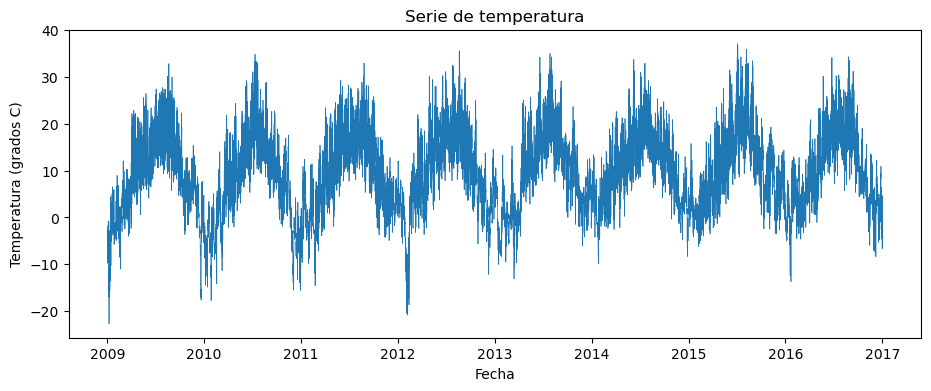

In [6]:
plt.figure(figsize=(11, 4))
plt.plot(datos["Date Time"], datos["temperatura"], linewidth=0.5)
plt.xlabel("Fecha")
plt.ylabel("Temperatura (grados C)")
plt.title("Serie de temperatura")
plt.show()

## 5. Preparacion de los datos

Se separa la serie cronologicamente: 70 por ciento para entrenamiento, 15 por ciento para validacion y 15 por ciento para prueba. No se mezclan las observaciones aleatoriamente.

La estandarizacion se ajusta solamente con los datos de entrenamiento. Luego se construyen ventanas de 24 observaciones para predecir la siguiente. Cada muestra de entrada tiene forma (24, 1), correspondiente a 24 pasos de tiempo y una variable.

In [7]:
LONGITUD = 24

serie = datos["temperatura"].to_numpy(dtype="float32")

n = len(serie)
fin_train = int(n * 0.70)
fin_val = int(n * 0.85)

escalador = StandardScaler()
escalador.fit(serie[:fin_train].reshape(-1, 1))
serie_escalada = escalador.transform(serie.reshape(-1, 1)).ravel()

X = np.array([serie_escalada[i:i + LONGITUD] for i in range(n - LONGITUD)], dtype="float32")
y = serie_escalada[LONGITUD:]
indices_objetivo = np.arange(LONGITUD, n)

#Las redes convolucionales 1D de Keras esperan que los datos de entrada tengan tres dimensiones:
#(No. de muestras, No. pasos temporales, No. de var predictoras)
X = X.reshape(-1, LONGITUD, 1)

X_train = X[indices_objetivo < fin_train]
y_train = y[indices_objetivo < fin_train]

X_val = X[(indices_objetivo >= fin_train) & (indices_objetivo < fin_val)]
y_val = y[(indices_objetivo >= fin_train) & (indices_objetivo < fin_val)]

X_test = X[indices_objetivo >= fin_val]
y_test = y[indices_objetivo >= fin_val]
fechas_test = datos["Date Time"].iloc[indices_objetivo[indices_objetivo >= fin_val]]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validacion:", X_val.shape, y_val.shape)
print("Prueba:", X_test.shape, y_test.shape)
print("Primera ventana:", X_train[0].ravel()[:5])

Entrenamiento: (49004, 24, 1) (49004,)
Validacion: (10506, 24, 1) (10506,)
Prueba: (10507, 24, 1) (10507,)
Primera ventana: [-2.013193  -1.9855454 -2.066328  -2.081752  -2.1340005]


## 6. Implementacion del modelo CNN 1D

La capa Conv1D identifica patrones locales en las temperaturas consecutivas. Flatten resume la informacion obtenida de los filtros. La capa Dense final produce la prediccion de temperatura estandarizada.

Se usa una sola capa convolucional para mantener el ejemplo sencillo.

In [19]:
def crear_modelo(filtros=16, kernel_size=3, dropout=0.1):
    modelo = Sequential([
        Input(shape=(LONGITUD, 1)),
        Conv1D(filters=filtros, kernel_size=kernel_size, activation="relu"),
        #GlobalMaxPooling1D(),
        Flatten(),
        Dropout(dropout),
        Dense(1)
    ])

    modelo.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return modelo

modelo_ejemplo = crear_modelo()
modelo_ejemplo.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_5 (Conv1D)                    │ (None, 22, 16)              │              64 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 352)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 352)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │             353 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 417 (1.63 KB)

 Trainable params: 417 (1.63 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Experimentos con hiperparametros

Se modifican solamente el numero de filtros y el tamano del kernel. Se mantiene la misma particion de los datos. El mejor modelo se seleccionara segun el RMSE de validacion, expresado en grados C.

EarlyStopping detiene el entrenamiento cuando la perdida de validacion deja de mejorar.

In [20]:
configuraciones = [
    {"filtros": 16, "kernel_size": 3},
    {"filtros": 32, "kernel_size": 3},
    {"filtros": 32, "kernel_size": 5}
]

resultados = []
modelos = []
historias = []

for i, config in enumerate(configuraciones):
    print("Experimento", i + 1, config)

    modelo = crear_modelo(**config)
    parada = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

    historia = modelo.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=12, batch_size=128,
                          shuffle=False, callbacks=[parada], verbose=0)

    pred_val = modelo.predict(X_val, verbose=0).ravel()
    real_val = escalador.inverse_transform(y_val.reshape(-1, 1)).ravel()
    pred_val = escalador.inverse_transform(pred_val.reshape(-1, 1)).ravel()

    mae = mean_absolute_error(real_val, pred_val)
    rmse = np.sqrt(mean_squared_error(real_val, pred_val))

    resultados.append({"experimento": i + 1, **config, "MAE_val": mae, "RMSE_val": rmse})
    modelos.append(modelo)
    historias.append(historia)

resultados_df = pd.DataFrame(resultados).sort_values("RMSE_val")
display(resultados_df.round(3))

Experimento 1 {'filtros': 16, 'kernel_size': 3}
Experimento 2 {'filtros': 32, 'kernel_size': 3}
Experimento 3 {'filtros': 32, 'kernel_size': 5}


,experimento,filtros,kernel_size,MAE_val,RMSE_val
1,2,32,3,0.558,0.743
2,3,32,5,0.565,0.754
0,1,16,3,0.566,0.772


## 8. Seleccion del mejor modelo

La seleccion depende exclusivamente del conjunto de validacion. El conjunto de prueba no participa en la comparacion de hiperparametros.

In [21]:
mejor_indice = int(resultados_df.iloc[0]["experimento"]) - 1
mejor_modelo = modelos[mejor_indice]
mejor_historia = historias[mejor_indice]

print("Mejor configuracion:")
print(configuraciones[mejor_indice])

Mejor configuracion:
{'filtros': 32, 'kernel_size': 3}


## 9. Analisis de resultados

Primero se revisan las curvas de entrenamiento y validacion. Una diferencia persistente entre ellas puede indicar sobreajuste. Despues se evalua el mejor modelo una sola vez sobre el conjunto de prueba.

Se calculan MAE, RMSE y R2 en la escala original de temperatura.

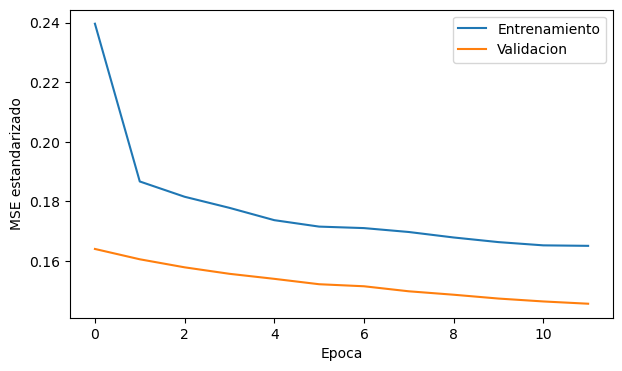

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(mejor_historia.history["loss"], label="Entrenamiento")
plt.plot(mejor_historia.history["val_loss"], label="Validacion")
plt.xlabel("Epoca")
plt.ylabel("MSE estandarizado")
plt.legend()
plt.show()

In [12]:
pred_test = mejor_modelo.predict(X_test, verbose=0).ravel()
real_test = escalador.inverse_transform(y_test.reshape(-1, 1)).ravel()
pred_test = escalador.inverse_transform(pred_test.reshape(-1, 1)).ravel()

mae_cnn = mean_absolute_error(real_test, pred_test)
rmse_cnn = np.sqrt(mean_squared_error(real_test, pred_test))
r2_cnn = r2_score(real_test, pred_test)

print("CNN 1D")
print("MAE:", round(mae_cnn, 3), "grados C")
print("RMSE:", round(rmse_cnn, 3), "grados C")
print("R2:", round(r2_cnn, 3))

CNN 1D
MAE: 2.463 grados C
RMSE: 3.062 grados C
R2: 0.845


Como referencia, se utiliza un modelo ingenuo que predice que la temperatura de la siguiente hora sera igual a la ultima temperatura observada. Esta comparacion permite juzgar si la CNN mejora una estrategia sencilla.

In [13]:
pred_base = escalador.inverse_transform(X_test[:, -1, 0].reshape(-1, 1)).ravel()

comparacion = pd.DataFrame({
    "modelo": ["Persistencia", "CNN 1D"],
    "MAE": [mean_absolute_error(real_test, pred_base), mae_cnn],
    "RMSE": [np.sqrt(mean_squared_error(real_test, pred_base)), rmse_cnn],
    "R2": [r2_score(real_test, pred_base), r2_cnn]
})

display(comparacion.round(3))

,modelo,MAE,RMSE,R2
0,Persistencia,0.644,0.901,0.987
1,CNN 1D,2.463,3.062,0.845


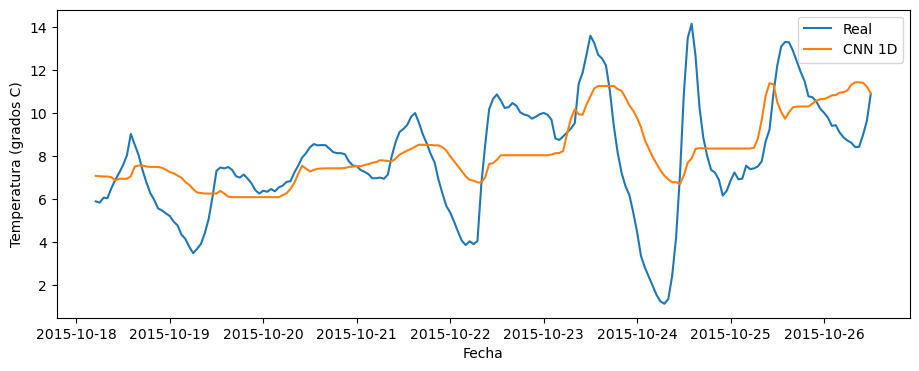

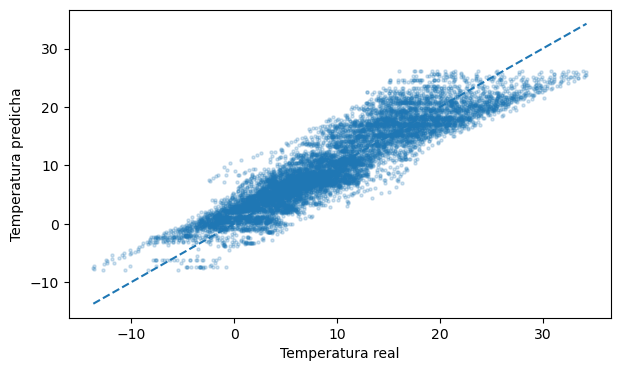

In [14]:
muestra = 200

plt.figure(figsize=(11, 4))
plt.plot(fechas_test.iloc[:muestra], real_test[:muestra], label="Real")
plt.plot(fechas_test.iloc[:muestra], pred_test[:muestra], label="CNN 1D")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (grados C)")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(real_test, pred_test, s=5, alpha=0.2)
limites = [min(real_test.min(), pred_test.min()), max(real_test.max(), pred_test.max())]
plt.plot(limites, limites, linestyle="--")
plt.xlabel("Temperatura real")
plt.ylabel("Temperatura predicha")
plt.show()

## 10. Prediccion de la siguiente hora

Se utiliza la ultima ventana disponible para estimar la temperatura de la siguiente observacion. La ventana se transforma con el mismo escalador del entrenamiento.

In [15]:
ultima_ventana = serie_escalada[-LONGITUD:].reshape(1, LONGITUD, 1)
pred_siguiente = mejor_modelo.predict(ultima_ventana, verbose=0)
pred_siguiente = escalador.inverse_transform(pred_siguiente)[0, 0]

print("Ultima temperatura observada:", round(float(serie[-1]), 2))
print("Prediccion para la siguiente hora aproximada:", round(float(pred_siguiente), 2))

Ultima temperatura observada: -4.82
Prediccion para la siguiente hora aproximada: -1.22
